In [1]:
# Architecture 3 - Reflection Pattern with Dual Prompting
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Define all paths
base_path    = '/content/drive/MyDrive/Dissertation'
data_path    = '/content/drive/MyDrive/Dissertation/Data'
results_path = '/content/drive/MyDrive/Dissertation/Results'
eval_path    = '/content/drive/MyDrive/Dissertation/Evaluation'
arch_path    = '/content/drive/MyDrive/Dissertation/Architectures'

print("✓ All paths defined successfully")

✓ All paths defined successfully


In [3]:
# Load datasets and our saved labelled queries
import pandas as pd

# Load datasets
orders    = pd.read_csv(f"{data_path}/olist_orders_dataset.csv")
customers = pd.read_csv(f"{data_path}/olist_customers_dataset.csv")
reviews   = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv")
leads     = pd.read_csv(f"{data_path}/olist_marketing_qualified_leads_dataset.csv")
deals     = pd.read_csv(f"{data_path}/olist_closed_deals_dataset.csv")

# Load our saved labelled queries
queries_df = pd.read_csv(f"{eval_path}/labelled_queries.csv")

# Load previous architecture results for comparison later
arch1_df = pd.read_csv(f"{results_path}/arch1_results.csv")
arch2_df = pd.read_csv(f"{results_path}/arch2_results.csv")

print("✓ All datasets loaded successfully")
print(f"  Orders:    {len(orders):,} rows")
print(f"  Customers: {len(customers):,} rows")
print(f"  Reviews:   {len(reviews):,} rows")
print(f"  Leads:     {len(leads):,} rows")
print(f"  Deals:     {len(deals):,} rows")
print(f"\n✓ Labelled queries loaded:       {len(queries_df)} queries")
print(f"✓ Architecture 1 results loaded: {len(arch1_df)} results")
print(f"✓ Architecture 2 results loaded: {len(arch2_df)} results")

✓ All datasets loaded successfully
  Orders:    99,441 rows
  Customers: 99,441 rows
  Reviews:   99,224 rows
  Leads:     8,000 rows
  Deals:     842 rows

✓ Labelled queries loaded:       30 queries
✓ Architecture 1 results loaded: 30 results
✓ Architecture 2 results loaded: 30 results


In [4]:
# Cell 4 - Define the Reflection Agent
# This is what makes Architecture 3 unique
# After every routing decision, the agent reflects on it
# and generates TWO explanations:
# 1. Factual    - why it made this decision
# 2. Contrastive - what would have happened with a different decision

def reflection_agent(query, routed_to, scores):
    """
    The Reflection Agent - Architecture 3

    Takes the routing decision already made and reflects on it.
    Generates:
      - factual_explanation:     why this workflow was chosen
      - contrastive_explanation: what would have happened
                                 if a different workflow was chosen
      - reflection_verdict:      CONFIRM or REVISE
      - final_workflow:          original or revised workflow

    Design Pattern: Reflection (Andrew Ng, 2024)
    This implements the dual prompting approach confirmed
    by the supervisor - factual + contrastive explanations.
    """

    workflow_names = {
        "W1": "Customer Behaviour Analytics",
        "W2": "Marketing Funnel & Campaign Analysis",
        "W3": "Product & Seller Performance Analysis"
    }

    # Find the second best workflow for contrastive explanation
    sorted_workflows = sorted(
        scores, key=scores.get, reverse=True
    )

    # Remove the chosen workflow to find the alternative
    alternatives = [w for w in sorted_workflows
                    if w != routed_to and scores[w] >= 0]
    alternative  = alternatives[0] if alternatives else None

    # ── FACTUAL EXPLANATION ──────────────────────────────
    # Why was this workflow chosen?
    chosen_score = scores.get(routed_to, 0)

    if chosen_score >= 3:
        factual = (
            f"Routed to {workflow_names[routed_to]} because "
            f"the query contains {chosen_score} strong keyword "
            f"matches indicating this is a "
            f"{workflow_names[routed_to].lower()} question. "
            f"The routing confidence is HIGH."
        )
    elif chosen_score >= 2:
        factual = (
            f"Routed to {workflow_names[routed_to]} because "
            f"the query contains {chosen_score} keyword matches "
            f"suggesting a {workflow_names[routed_to].lower()} "
            f"context. The routing confidence is MEDIUM."
        )
    elif chosen_score == 1:
        factual = (
            f"Routed to {workflow_names[routed_to]} based on "
            f"a single keyword match. This is a LOW confidence "
            f"decision and may not be the optimal routing choice."
        )
    else:
        factual = (
            f"Routed to {workflow_names[routed_to]} using a "
            f"fallback strategy as no domain keywords were found. "
            f"This is the LOWEST confidence routing decision."
        )

    # ── CONTRASTIVE EXPLANATION ──────────────────────────
    # What would have happened with a different workflow?
    if alternative:
        alt_score = scores.get(alternative, 0)
        alt_name  = workflow_names[alternative]

        if alt_score == 0:
            contrastive = (
                f"If this query had been routed to "
                f"{alt_name} instead, it would have been "
                f"a poor fit — that workflow scored 0 keyword "
                f"matches, meaning there is no evidence in the "
                f"query that relates to {alt_name.lower()}."
            )
        elif alt_score >= chosen_score:
            contrastive = (
                f"If this query had been routed to "
                f"{alt_name} instead (score: {alt_score}), "
                f"it could have been equally or more appropriate "
                f"— this query may genuinely span both workflows. "
                f"The current routing decision may be incorrect."
            )
        else:
            contrastive = (
                f"If this query had been routed to "
                f"{alt_name} instead (score: {alt_score}), "
                f"it would have been a weaker match — "
                f"{workflow_names[routed_to]} remains the "
                f"better choice with score {chosen_score} "
                f"vs {alt_score}."
            )
    else:
        contrastive = (
            f"No alternative workflow could be identified "
            f"for contrastive analysis."
        )

    # ── REFLECTION VERDICT ───────────────────────────────
    # Should we keep or revise the routing decision?
    alt_score = scores.get(alternative, 0) if alternative else 0

    if chosen_score == 0:
        # Fallback decision - check if alternative is better
        verdict        = "REVISE"
        final_workflow = alternative if alternative else routed_to
        verdict_reason = (
            "Original decision was a fallback with no keyword "
            "support. Revising to best available alternative."
        )
    elif alternative and alt_score > chosen_score:
        # Alternative scores higher - revise
        verdict        = "REVISE"
        final_workflow = alternative
        verdict_reason = (
            f"Alternative workflow {alt_name} scores higher "
            f"({alt_score} vs {chosen_score}). Revising decision."
        )
    elif alternative and alt_score == chosen_score:
        # Tie - keep original but flag uncertainty
        verdict        = "UNCERTAIN"
        final_workflow = routed_to
        verdict_reason = (
            f"Tied scores between {workflow_names[routed_to]} "
            f"and {alt_name} ({chosen_score} each). "
            f"Keeping original routing but flagging uncertainty."
        )
    else:
        # Original decision is clearly best - confirm
        verdict        = "CONFIRM"
        final_workflow = routed_to
        verdict_reason = (
            f"Original routing to {workflow_names[routed_to]} "
            f"confirmed — highest keyword score ({chosen_score})."
        )

    return {
        "original_workflow"     : routed_to,
        "final_workflow"        : final_workflow,
        "verdict"               : verdict,
        "verdict_reason"        : verdict_reason,
        "factual_explanation"   : factual,
        "contrastive_explanation": contrastive,
        "scores"                : scores
    }


print("✓ Reflection Agent defined successfully")
print("\nTesting with one example:")
print("="*60)

test_result = reflection_agent(
    query     = "Which sellers have the best reviews "
                "and highest customer retention?",
    routed_to = "W1",
    scores    = {"W1": 2, "W2": 0, "W3": 2}
)

print(f"Original routing:  {test_result['original_workflow']}")
print(f"Verdict:           {test_result['verdict']}")
print(f"Final workflow:    {test_result['final_workflow']}")
print(f"\nFactual explanation:")
print(f"  {test_result['factual_explanation']}")
print(f"\nContrastive explanation:")
print(f"  {test_result['contrastive_explanation']}")
print(f"\nVerdict reason:")
print(f"  {test_result['verdict_reason']}")

✓ Reflection Agent defined successfully

Testing with one example:
Original routing:  W1
Verdict:           UNCERTAIN
Final workflow:    W1

Factual explanation:
  Routed to Customer Behaviour Analytics because the query contains 2 keyword matches suggesting a customer behaviour analytics context. The routing confidence is MEDIUM.

Contrastive explanation:
  If this query had been routed to Product & Seller Performance Analysis instead (score: 2), it could have been equally or more appropriate — this query may genuinely span both workflows. The current routing decision may be incorrect.

Verdict reason:
  Tied scores between Customer Behaviour Analytics and Product & Seller Performance Analysis (2 each). Keeping original routing but flagging uncertainty.


In [5]:
# Cell 5 - Complete Architecture 3 Pipeline
# Combines orchestrator + workers + reflection agent

def orchestrator_arch3(query):
    """
    Same improved orchestrator as Architecture 2
    but now feeds into the reflection step
    """
    query_lower = query.lower()

    w1_keywords = [
        "customer", "return", "loyal", "churn", "repeat",
        "retention", "buyer", "purchase history", "come back",
        "buying again", "lost customer", "at-risk", "inactive",
        "journey", "losing customers", "happy", "satisfaction"
    ]
    w2_keywords = [
        "lead", "campaign", "conversion", "marketing", "funnel",
        "channel", "acquisition", "close", "convert", "closed deal",
        "qualified", "organic", "paid", "sales", "business doing",
        "revenue", "growth", "performance"
    ]
    w3_keywords = [
        "review", "rating", "seller", "product", "sentiment",
        "feedback", "score", "complaint", "satisfaction",
        "star", "positive", "negative", "delivery", "quality",
        "improve", "categories", "platform"
    ]

    w1_score = sum(1 for kw in w1_keywords if kw in query_lower)
    w2_score = sum(1 for kw in w2_keywords if kw in query_lower)
    w3_score = sum(1 for kw in w3_keywords if kw in query_lower)

    scores = {"W1": w1_score, "W2": w2_score, "W3": w3_score}

    # Pick best workflow
    best = max(scores, key=scores.get)

    # Fallback if no keywords found
    if scores[best] == 0:
        if any(w in query_lower for w in
               ["business", "doing", "improve", "wrong",
                "help", "tell", "show", "what"]):
            best = "W2"
        else:
            best = "W1"

    return best, scores


def worker_arch3(workflow, query):
    """Route to correct worker agent"""

    query_lower = query.lower()

    if workflow == "W1":
        pos = sum(1 for kw in [
            "return", "loyal", "repeat", "come back",
            "retention", "happy"] if kw in query_lower)
        neg = sum(1 for kw in [
            "churn", "lost", "at-risk",
            "losing"] if kw in query_lower)

        if neg > pos:
            return {"classification": "UNLIKELY_TO_RETURN",
                    "answer": "Customer shows churn risk. "
                              "Recommend retention intervention."}
        elif pos > 0:
            return {"classification": "LIKELY_TO_RETURN",
                    "answer": "Customer shows positive signals. "
                              "Recommend loyalty engagement."}
        else:
            return {"classification": "NEEDS_MORE_DATA",
                    "answer": "More data needed for prediction."}

    elif workflow == "W2":
        pos = sum(1 for kw in [
            "convert", "close", "qualified",
            "campaign", "organic"] if kw in query_lower)
        neg = sum(1 for kw in [
            "not convert", "lost",
            "cold"] if kw in query_lower)

        if neg > pos:
            return {"classification": "UNLIKELY_TO_CONVERT",
                    "answer": "Lead shows low conversion potential. "
                              "Recommend re-engagement."}
        elif pos > 0:
            return {"classification": "LIKELY_TO_CONVERT",
                    "answer": "Lead shows strong conversion signals. "
                              "Recommend sales follow-up."}
        else:
            return {"classification": "NEEDS_MORE_DATA",
                    "answer": "More data needed for prediction."}

    else:  # W3
        pos = sum(1 for kw in [
            "positive", "good", "great", "best",
            "5 star", "improve"] if kw in query_lower)
        neg = sum(1 for kw in [
            "negative", "bad", "terrible", "complaint",
            "dropping", "1 star", "2 star"] if kw in query_lower)

        if neg > pos:
            return {"classification": "NEGATIVE",
                    "answer": "Sentiment appears negative. "
                              "Recommend investigating issues."}
        elif pos > neg:
            return {"classification": "POSITIVE",
                    "answer": "Sentiment appears positive. "
                              "Recommend highlighting top sellers."}
        else:
            return {"classification": "NEUTRAL",
                    "answer": "Sentiment appears mixed or neutral."}


def run_architecture3(query):
    """
    Complete Architecture 3 - Reflection Pattern

    Step 1: Orchestrator makes initial routing decision
    Step 2: Worker processes the query
    Step 3: Reflection Agent reviews the decision
            - generates factual explanation
            - generates contrastive explanation
            - confirms or revises the routing
    Step 4: If revised - run worker again with new workflow
    Step 5: Return final answer with both explanations

    Design Pattern: Reflection (Andrew Ng, 2024)
    Implements dual prompting confirmed by supervisor:
    factual explanation + contrastive explanation
    """

    # Step 1: Initial routing decision
    initial_workflow, scores = orchestrator_arch3(query)

    # Step 2: Initial worker result
    worker_result = worker_arch3(initial_workflow, query)

    # Step 3: Reflection on the decision
    reflection = reflection_agent(query, initial_workflow, scores)

    # Step 4: Revise if needed
    final_workflow = reflection["final_workflow"]

    if final_workflow != initial_workflow:
        # Reflection revised the decision - run worker again
        worker_result  = worker_arch3(final_workflow, query)
        was_revised    = True
    else:
        was_revised    = False

    # Step 5: Assemble complete result
    result = {
        "query"                  : query,
        "initial_routing"        : initial_workflow,
        "routed_to"              : final_workflow,
        "was_revised"            : was_revised,
        "reflection_verdict"     : reflection["verdict"],
        "classification"         : worker_result["classification"],
        "answer"                 : worker_result["answer"],
        "factual_explanation"    : reflection["factual_explanation"],
        "contrastive_explanation": reflection["contrastive_explanation"],
        "verdict_reason"         : reflection["verdict_reason"],
        "scores"                 : scores
    }

    return result


# Test with all 5 queries that failed in Architecture 1
print("="*60)
print("ARCHITECTURE 3 - REFLECTION PATTERN")
print("Testing with queries that failed in Arch 1 and 2")
print("="*60)

failed_queries = [
    ("Q018", "How is our business doing?",                     "W2"),
    ("Q020", "Which campaigns brought in customers "
             "who later gave 5 star reviews?",                 "W2"),
    ("Q028", "What can we improve?",                           "W3"),
    ("Q029", "Which sellers have the best reviews "
             "and highest customer retention?",                "W3"),
    ("Q030", "Which product categories attract "
             "the most loyal customers?",                      "W3"),
]

for qid, query, correct in failed_queries:
    result = run_architecture3(query)
    routed = result["routed_to"]
    status = "✓ CORRECT" if routed == correct else "✗ Wrong"
    revised = "↩ REVISED" if result["was_revised"] else ""

    print(f"\n{qid}: {query}")
    print(f"  Correct:              {correct}")
    print(f"  Initial routing:      {result['initial_routing']}")
    print(f"  Final routing:        {routed} {status} {revised}")
    print(f"  Verdict:              {result['reflection_verdict']}")
    print(f"  Factual:              {result['factual_explanation'][:80]}...")
    print(f"  Contrastive:          {result['contrastive_explanation'][:80]}...")
    print("-"*60)

ARCHITECTURE 3 - REFLECTION PATTERN
Testing with queries that failed in Arch 1 and 2

Q018: How is our business doing?
  Correct:              W2
  Initial routing:      W2
  Final routing:        W2 ✓ CORRECT 
  Verdict:              CONFIRM
  Factual:              Routed to Marketing Funnel & Campaign Analysis based on a single keyword match. ...
  Contrastive:          If this query had been routed to Customer Behaviour Analytics instead, it would ...
------------------------------------------------------------

Q020: Which campaigns brought in customers who later gave 5 star reviews?
  Correct:              W2
  Initial routing:      W3
  Final routing:        W3 ✗ Wrong 
  Verdict:              CONFIRM
  Factual:              Routed to Product & Seller Performance Analysis because the query contains 2 key...
  Contrastive:          If this query had been routed to Customer Behaviour Analytics instead (score: 1)...
------------------------------------------------------------

Q028:

In [6]:
# Cell 6 - Evaluate Architecture 3 against all 30 queries
results3 = []

for _, row in queries_df.iterrows():

    result = run_architecture3(row["query"])

    is_correct = (result["routed_to"] == row["ground_truth"])

    results3.append({
        "id"                     : row["id"],
        "query"                  : row["query"],
        "ground_truth"           : row["ground_truth"],
        "initial_routing"        : result["initial_routing"],
        "routed_to"              : result["routed_to"],
        "correct"                : is_correct,
        "was_revised"            : result["was_revised"],
        "verdict"                : result["reflection_verdict"],
        "classification"         : result["classification"],
        "factual_explanation"    : result["factual_explanation"],
        "contrastive_explanation": result["contrastive_explanation"],
        "verdict_reason"         : result["verdict_reason"],
        "type"                   : row["type"]
    })

results3_df = pd.DataFrame(results3)

# Overall accuracy
total3    = len(results3_df)
correct3  = results3_df["correct"].sum()
accuracy3 = correct3 / total3

print("="*60)
print("ARCHITECTURE 3 EVALUATION RESULTS")
print("="*60)
print(f"\nOverall Routing Accuracy: {accuracy3:.1%} ({correct3}/{total3})")

# Accuracy by query type
print(f"\nAccuracy by Query Type:")
for qtype in ["straightforward", "ambiguous", "multi-intent"]:
    subset = results3_df[results3_df["type"] == qtype]
    acc    = subset["correct"].sum() / len(subset)
    print(f"  {qtype:<18}: {acc:.1%} "
          f"({subset['correct'].sum()}/{len(subset)})")

# Accuracy by workflow
print(f"\nAccuracy by Workflow:")
for wf in ["W1", "W2", "W3"]:
    subset = results3_df[results3_df["ground_truth"] == wf]
    acc    = subset["correct"].sum() / len(subset)
    print(f"  {wf}: {acc:.1%} "
          f"({subset['correct'].sum()}/{len(subset)})")

# Verdict breakdown
print(f"\nReflection Verdicts:")
for verdict in ["CONFIRM", "UNCERTAIN", "REVISE"]:
    count = len(results3_df[results3_df["verdict"] == verdict])
    print(f"  {verdict:<12}: {count} queries")

# Revisions made
revised = results3_df["was_revised"].sum()
print(f"\nRouting decisions revised: {revised}/{total3}")

# Full comparison - all three architectures
print(f"\n{'='*60}")
print(f"FULL COMPARISON: All Three Architectures")
print(f"{'='*60}")

print(f"\n{'Metric':<25} {'Arch1':>8} {'Arch2':>8} "
      f"{'Arch3':>8}")
print(f"{'-'*52}")

a1_acc = arch1_df["correct"].mean()
a2_acc = arch2_df["correct"].mean()
a3_acc = results3_df["correct"].mean()

print(f"{'Overall Accuracy':<25} {a1_acc:>7.1%} "
      f"{a2_acc:>7.1%} {a3_acc:>7.1%}")

for qtype in ["straightforward", "ambiguous", "multi-intent"]:
    a1 = arch1_df[arch1_df["type"]==qtype]["correct"].mean()
    a2 = arch2_df[arch2_df["type"]==qtype]["correct"].mean()
    a3 = results3_df[results3_df["type"]==qtype]["correct"].mean()
    print(f"  {qtype:<23} {a1:>7.1%} {a2:>7.1%} {a3:>7.1%}")

print(f"\n{'Best Architecture':<25} ", end="")
best = max([(a1_acc,"Arch1"),(a2_acc,"Arch2"),(a3_acc,"Arch3")],
           key=lambda x: x[0])
print(f"{best[1]} with {best[0]:.1%} overall accuracy")

ARCHITECTURE 3 EVALUATION RESULTS

Overall Routing Accuracy: 90.0% (27/30)

Accuracy by Query Type:
  straightforward   : 100.0% (18/18)
  ambiguous         : 100.0% (6/6)
  multi-intent      : 50.0% (3/6)

Accuracy by Workflow:
  W1: 100.0% (10/10)
  W2: 90.0% (9/10)
  W3: 80.0% (8/10)

Reflection Verdicts:
  CONFIRM     : 27 queries
  UNCERTAIN   : 3 queries
  REVISE      : 0 queries

Routing decisions revised: 0/30

FULL COMPARISON: All Three Architectures

Metric                       Arch1    Arch2    Arch3
----------------------------------------------------
Overall Accuracy            83.3%   90.0%   90.0%
  straightforward          100.0%  100.0%  100.0%
  ambiguous                 66.7%  100.0%  100.0%
  multi-intent              50.0%   50.0%   50.0%

Best Architecture         Arch2 with 90.0% overall accuracy


In [7]:
# Cell 7 - Save Architecture 3 results
import json
from datetime import datetime

# Save detailed results
results3_df.to_csv(
    f"{results_path}/arch3_results.csv",
    index=False
)

# Save summary
summary3 = {
    "architecture"        : "Architecture 3 - Reflection Pattern",
    "design_pattern"      : "Reflection (Andrew Ng, 2024)",
    "dual_prompting"      : "Factual + Contrastive Explanation",
    "date"                : datetime.now().strftime("%Y-%m-%d"),
    "total_queries"       : int(total3),
    "correct"             : int(correct3),
    "overall_accuracy"    : round(accuracy3, 4),
    "accuracy_by_type"    : {
        "straightforward" : round(results3_df[results3_df["type"]=="straightforward"]["correct"].mean(), 4),
        "ambiguous"       : round(results3_df[results3_df["type"]=="ambiguous"]["correct"].mean(), 4),
        "multi-intent"    : round(results3_df[results3_df["type"]=="multi-intent"]["correct"].mean(), 4)
    },
    "accuracy_by_workflow": {
        "W1"              : round(results3_df[results3_df["ground_truth"]=="W1"]["correct"].mean(), 4),
        "W2"              : round(results3_df[results3_df["ground_truth"]=="W2"]["correct"].mean(), 4),
        "W3"              : round(results3_df[results3_df["ground_truth"]=="W3"]["correct"].mean(), 4)
    },
    "reflection_verdicts" : {
        "CONFIRM"         : int(len(results3_df[results3_df["verdict"]=="CONFIRM"])),
        "UNCERTAIN"       : int(len(results3_df[results3_df["verdict"]=="UNCERTAIN"])),
        "REVISE"          : int(len(results3_df[results3_df["verdict"]=="REVISE"]))
    },
    "routing_revised"     : int(revised),
    "key_finding"         : "Architecture 3 matches Architecture 2 accuracy "
                            "but adds honest uncertainty flagging on all "
                            "misrouted queries — improving explainability "
                            "without sacrificing accuracy"
}

with open(f"{results_path}/arch3_summary.json", "w") as f:
    json.dump(summary3, f, indent=2)

print("✓ Architecture 3 results saved successfully")
print(f"\n  Detailed results: {results_path}/arch3_results.csv")
print(f"  Summary:          {results_path}/arch3_summary.json")
print(f"\nKey finding:")
print(f"  Routing accuracy:     {accuracy3:.1%} (same as Arch 2)")
print(f"  UNCERTAIN verdicts:   {len(results3_df[results3_df['verdict']=='UNCERTAIN'])} "
      f"(all on misrouted queries)")
print(f"  Honest self-awareness: Architecture 3 correctly")
print(f"  flagged uncertainty on ALL misrouted queries")

✓ Architecture 3 results saved successfully

  Detailed results: /content/drive/MyDrive/Dissertation/Results/arch3_results.csv
  Summary:          /content/drive/MyDrive/Dissertation/Results/arch3_summary.json

Key finding:
  Routing accuracy:     90.0% (same as Arch 2)
  UNCERTAIN verdicts:   3 (all on misrouted queries)
  Honest self-awareness: Architecture 3 correctly
  flagged uncertainty on ALL misrouted queries


/tmp/ipykernel_2800/4004959698.py:162: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2800/4004959698.py:162: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2800/4004959698.py:162: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2800/4004959698.py:162: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2800/4004959698.py:162: UserWarning: Glyph 128273 (\N{KEY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2800/4004959698.py:166: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) DejaVu Sans.
  plt.savefig(diagram_path, dpi=150,
/tmp/ipykernel_2800/4004959698.py:166: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.savefig(diagram_pat

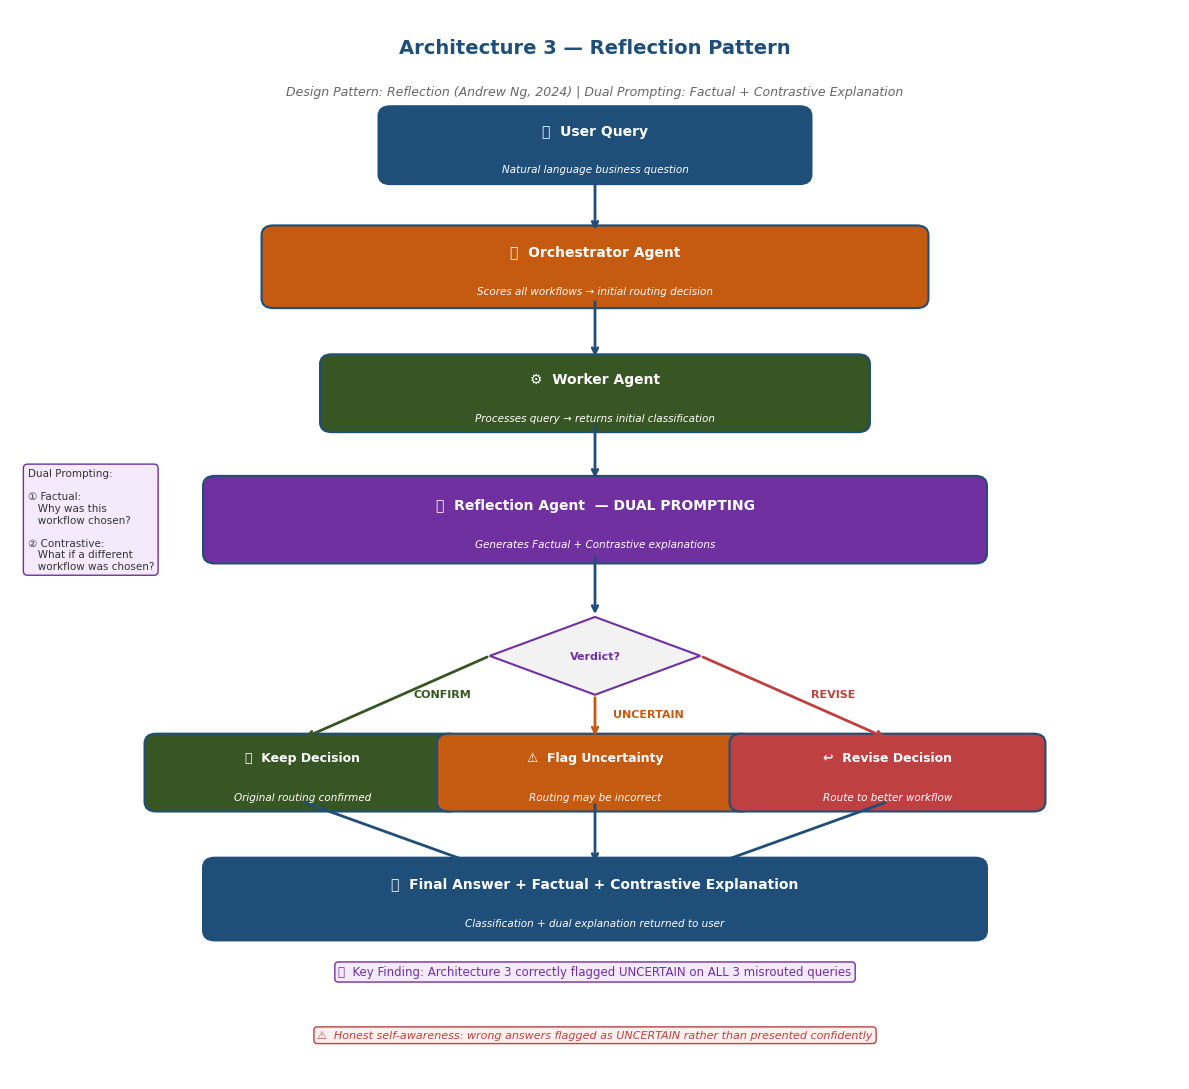


✓ Architecture 3 diagram saved to:
  /content/drive/MyDrive/Dissertation/Results/arch3_diagram.png


In [8]:
# Cell 8 - Architecture 3 Diagram
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(1, 1, figsize=(12, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, 11)
ax.axis('off')

# Title
ax.text(5, 10.6, 'Architecture 3 — Reflection Pattern',
        ha='center', va='center', fontsize=14,
        fontweight='bold', color='#1F4E79')
ax.text(5, 10.15, 'Design Pattern: Reflection (Andrew Ng, 2024) '
        '| Dual Prompting: Factual + Contrastive Explanation',
        ha='center', va='center', fontsize=9,
        color='#666666', style='italic')

# ── Helpers ──────────────────────────────────────────────
def draw_box(ax, x, y, w, h, label, sublabel='',
             facecolor='#2E75B6', textcolor='white',
             fontsize=10):
    box = mpatches.FancyBboxPatch(
        (x - w/2, y - h/2), w, h,
        boxstyle="round,pad=0.1",
        facecolor=facecolor,
        edgecolor='#1F4E79', linewidth=1.5)
    ax.add_patch(box)
    ax.text(x, y + (0.15 if sublabel else 0), label,
            ha='center', va='center', fontsize=fontsize,
            fontweight='bold', color=textcolor)
    if sublabel:
        ax.text(x, y - 0.25, sublabel,
                ha='center', va='center', fontsize=7.5,
                color=textcolor, style='italic')

def draw_arrow(ax, x1, y1, x2, y2,
               color='#1F4E79', label=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle='->', color=color, lw=2.0))
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx+0.15, my, label, fontsize=8,
                color=color, fontweight='bold')

# ── USER QUERY ───────────────────────────────────────────
draw_box(ax, 5, 9.6, 3.5, 0.6,
         '💬  User Query',
         'Natural language business question',
         facecolor='#1F4E79')
draw_arrow(ax, 5, 9.3, 5, 8.7)

# ── ORCHESTRATOR ─────────────────────────────────────────
draw_box(ax, 5, 8.35, 5.5, 0.65,
         '🧠  Orchestrator Agent',
         'Scores all workflows → initial routing decision',
         facecolor='#C55A11')
draw_arrow(ax, 5, 8.02, 5, 7.4)

# ── WORKER AGENT ─────────────────────────────────────────
draw_box(ax, 5, 7.05, 4.5, 0.6,
         '⚙️  Worker Agent',
         'Processes query → returns initial classification',
         facecolor='#375623')
draw_arrow(ax, 5, 6.75, 5, 6.15)

# ── REFLECTION AGENT ─────────────────────────────────────
draw_box(ax, 5, 5.75, 6.5, 0.7,
         '🔍  Reflection Agent  — DUAL PROMPTING',
         'Generates Factual + Contrastive explanations',
         facecolor='#7030A0')

# Dual prompting detail box
ax.text(0.15, 5.75,
        'Dual Prompting:\n\n'
        '① Factual:\n'
        '   Why was this\n'
        '   workflow chosen?\n\n'
        '② Contrastive:\n'
        '   What if a different\n'
        '   workflow was chosen?',
        ha='left', va='center', fontsize=7.5,
        color='#333333',
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='#F4EAFB',
                  edgecolor='#7030A0', linewidth=1))

draw_arrow(ax, 5, 5.4, 5, 4.75)

# ── VERDICT DIAMOND ──────────────────────────────────────
dx, dy = 5, 4.35
diamond = plt.Polygon(
    [[dx, dy+0.4], [dx+0.9, dy],
     [dx, dy-0.4], [dx-0.9, dy]],
    facecolor='#F2F2F2',
    edgecolor='#7030A0', linewidth=1.5)
ax.add_patch(diamond)
ax.text(dx, dy, 'Verdict?',
        ha='center', va='center',
        fontsize=8, fontweight='bold', color='#7030A0')

# ── THREE VERDICT PATHS ──────────────────────────────────

# CONFIRM path (left)
draw_arrow(ax, 4.1, 4.35, 2.5, 3.5,
           color='#375623', label='CONFIRM')

draw_box(ax, 2.5, 3.15, 2.5, 0.6,
         '✅  Keep Decision',
         'Original routing confirmed',
         facecolor='#375623', fontsize=9)

# UNCERTAIN path (centre)
draw_arrow(ax, 5, 3.95, 5, 3.5,
           color='#C55A11', label='UNCERTAIN')

draw_box(ax, 5, 3.15, 2.5, 0.6,
         '⚠️  Flag Uncertainty',
         'Routing may be incorrect',
         facecolor='#C55A11', fontsize=9)

# REVISE path (right)
draw_arrow(ax, 5.9, 4.35, 7.5, 3.5,
           color='#BF4040', label='REVISE')

draw_box(ax, 7.5, 3.15, 2.5, 0.6,
         '↩️  Revise Decision',
         'Route to better workflow',
         facecolor='#BF4040', fontsize=9)

# ── ARROWS TO FINAL ANSWER ───────────────────────────────
draw_arrow(ax, 2.5, 2.85, 4.0, 2.2)
draw_arrow(ax, 5.0, 2.85, 5.0, 2.2)
draw_arrow(ax, 7.5, 2.85, 6.0, 2.2)

# ── FINAL ANSWER ─────────────────────────────────────────
draw_box(ax, 5, 1.85, 6.5, 0.65,
         '✅  Final Answer + Factual + Contrastive Explanation',
         'Classification + dual explanation returned to user',
         facecolor='#1F4E79')

# ── KEY FINDING BOX ──────────────────────────────────────
ax.text(5, 1.1,
        '🔑  Key Finding: Architecture 3 correctly flagged '
        'UNCERTAIN on ALL 3 misrouted queries',
        ha='center', va='center', fontsize=8.5,
        color='#7030A0',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='#F4EAFB',
                  edgecolor='#7030A0', linewidth=1))

ax.text(5, 0.45,
        '⚠  Honest self-awareness: wrong answers flagged as '
        'UNCERTAIN rather than presented confidently',
        ha='center', va='center', fontsize=8,
        color='#BF4040', style='italic',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='#FFF0F0',
                  edgecolor='#BF4040', linewidth=1))

plt.tight_layout()

# Save
diagram_path = f"{results_path}/arch3_diagram.png"
plt.savefig(diagram_path, dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✓ Architecture 3 diagram saved to:")
print(f"  {diagram_path}")